#### 최신 모델 성능 실험#2 (SensitiveMamba;2026)

##### 1) 환경설정

In [ ]:
import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

# Configuration
CONFIG = {
    "data_dir": "assets/SKAB_0.9.0/",
    "window_size": 100,
    "stride": 1,
    "hidden_dim": 64,
    "state_dim": 16,
    "num_layers": 2,
    "dropout": 0.1,
    "batch_size": 64,
    "epochs": 100,
    "learning_rate": 1e-3,
    "weight_decay": 1e-5,
    "contrastive_weight": 0.1,
    "temperature": 0.2,
    "patience": 15,
}

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)

##### 2) Mamba 라이브러리 설치

In [ ]:
from mamba_ssm import Mamba

print("Mamba successfully imported.")

##### 3) SKAB 0.9 데이터셋 호출

In [ ]:
DATA_DIR = Path(CONFIG["data_dir"])

SENSOR_COLUMNS = [
    "Accelerometer1RMS",
    "Accelerometer2RMS",
    "Current",
    "Pressure",
    "Temperature",
    "Thermocouple",
    "Voltage",
    "RateRMS"
]

def load_skab(data_dir):

    files = sorted(data_dir.glob("*.csv"))

    if not files:
        raise FileNotFoundError(
            f"No CSV files found in {data_dir}"
        )

    experiments = {}

    for file in files:

        df = pd.read_csv(file)

        required = (
            SENSOR_COLUMNS +
            ["anomaly", "changepoint"]
        )

        missing = [
            col for col in required
            if col not in df.columns
        ]

        if missing:
            print(f"Skipping {file.name}: {missing}")
            continue

        df = df[required].copy()

        df[SENSOR_COLUMNS] = (
            df[SENSOR_COLUMNS]
            .apply(pd.to_numeric, errors="coerce")
        )

        df = df.replace(
            [np.inf, -np.inf], np.nan
        )

        df = df.dropna().reset_index(drop=True)

        df["anomaly"] = df["anomaly"].astype(int)
        df["changepoint"] = (
            df["changepoint"].astype(int)
        )

        experiments[file.name] = df

    return experiments


experiments = load_skab(DATA_DIR)

print("Number of experiments:", len(experiments))

for name, df in list(experiments.items())[:3]:
    print(
        name,
        "Shape:", df.shape,
        "Anomalies:", df["anomaly"].sum()
    )

##### 4) 데이터셋 탐색

In [ ]:
all_data = pd.concat(
    [
        df.assign(experiment=name)
        for name, df in experiments.items()
    ],
    ignore_index=True
)

print(all_data.shape)

print("\nAnomaly distribution:")
print(all_data["anomaly"].value_counts())

fig, axes = plt.subplots(
    2, 1, figsize=(15, 8)
)

sns.countplot(
    data=all_data,
    x="anomaly",
    ax=axes[0]
)

axes[0].set_title("Point anomaly distribution")

sample = next(iter(experiments.values()))

axes[1].plot(
    sample["Pressure"].values,
    label="Pressure"
)

axes[1].set_title("Example sensor sequence")
axes[1].legend()

plt.tight_layout()
plt.show()

##### 5) 데이터셋 분할

In [ ]:
from sklearn.model_selection import train_test_split

file_names = sorted(experiments.keys())

train_files, temp_files = train_test_split(
    file_names,
    test_size=0.4,
    random_state=SEED
)

val_files, test_files = train_test_split(
    temp_files,
    test_size=0.5,
    random_state=SEED
)

print("Training experiments:", len(train_files))
print("Validation experiments:", len(val_files))
print("Testing experiments:", len(test_files))

print("\nTrain:", train_files)
print("\nValidation:", val_files)
print("\nTest:", test_files)

##### 6) 준지도학습 (normal-only)

In [18]:
scaler = StandardScaler()

normal_train_values = []

for name in train_files:

    df = experiments[name]

    normal = df[
        df["anomaly"] == 0
    ]

    normal_train_values.append(
        normal[SENSOR_COLUMNS].values
    )

normal_train_values = np.concatenate(
    normal_train_values,
    axis=0
)

scaler.fit(normal_train_values)

print("Scaler fitted using normal training data only.")
print("Mean:", scaler.mean_)
print("Scale:", scaler.scale_)

NameError: name 'train_files' is not defined

##### 7) 윈도우 생성

In [ ]:
WINDOW = CONFIG["window_size"]
STRIDE = CONFIG["stride"]

def transform_experiment(df):

    x = scaler.transform(
        df[SENSOR_COLUMNS].values
    ).astype(np.float32)

    y = df["anomaly"].values.astype(np.int64)

    return x, y


def create_normal_windows(x, y):

    windows = []

    normal_indices = np.where(y == 0)[0]

    if len(normal_indices) == 0:
        return np.empty(
            (0, WINDOW, x.shape[1]),
            dtype=np.float32
        )

    # Divide normal points into contiguous segments.
    segments = np.split(
        normal_indices,
        np.where(np.diff(normal_indices) != 1)[0] + 1
    )

    for segment in segments:

        if len(segment) < WINDOW:
            continue

        for start in range(
            0,
            len(segment) - WINDOW + 1,
            STRIDE
        ):

            idx = segment[start:start + WINDOW]

            windows.append(x[idx])

    if not windows:
        return np.empty(
            (0, WINDOW, x.shape[1]),
            dtype=np.float32
        )

    return np.stack(windows)


def create_test_windows(x, y):

    windows = []
    labels = []

    for start in range(
        0,
        len(x) - WINDOW + 1,
        STRIDE
    ):

        end = start + WINDOW

        windows.append(x[start:end])

        # Evaluate the final time step of each window.
        labels.append(y[end - 1])

    return (
        np.asarray(windows, dtype=np.float32),
        np.asarray(labels, dtype=np.int64)
    )


X_train_list = []
X_val_list = []
X_test_list = []
Y_test_list = []

for name in train_files:

    x, y = transform_experiment(experiments[name])

    w = create_normal_windows(x, y)

    if len(w):
        X_train_list.append(w)


for name in val_files:

    x, y = transform_experiment(experiments[name])

    w = create_normal_windows(x, y)

    if len(w):
        X_val_list.append(w)


for name in test_files:

    x, y = transform_experiment(experiments[name])

    w, labels = create_test_windows(x, y)

    if len(w):
        X_test_list.append(w)
        Y_test_list.append(labels)


X_train = np.concatenate(X_train_list, axis=0)
X_val = np.concatenate(X_val_list, axis=0)
X_test = np.concatenate(X_test_list, axis=0)
y_test = np.concatenate(Y_test_list, axis=0)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)
print("Test anomaly ratio:", y_test.mean())

##### 8) pytorch 데이터셋 및 로더 준비

In [ ]:
class SKABDataset(Dataset):

    def __init__(self, data):
        self.data = torch.tensor(
            data, dtype=torch.float32
        )

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]


train_dataset = SKABDataset(X_train)
val_dataset = SKABDataset(X_val)
test_dataset = SKABDataset(X_test)

train_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=0
)

print("DataLoaders ready.")

##### 9) 구조적 contrasive learning

In [ ]:
def augment_sequence(x):

    noise = torch.randn_like(x) * 0.02

    scale = (
        1.0 +
        torch.randn(
            x.size(0), 1, x.size(2),
            device=x.device
        ) * 0.05
    )

    return x * scale + noise


def nt_xent_loss(z1, z2, temperature=0.2):

    z1 = F.normalize(z1, dim=1)
    z2 = F.normalize(z2, dim=1)

    batch_size = z1.size(0)

    z = torch.cat([z1, z2], dim=0)

    similarity = torch.mm(z, z.T)

    similarity = similarity / temperature

    mask = torch.eye(
        2 * batch_size,
        device=z.device,
        dtype=torch.bool
    )

    similarity = similarity.masked_fill(
        mask, -1e9
    )

    targets = torch.cat([
        torch.arange(
            batch_size, 2 * batch_size,
            device=z.device
        ),
        torch.arange(
            batch_size,
            device=z.device
        )
    ])

    return F.cross_entropy(
        similarity, targets
    )


def hierarchical_contrastive_loss(
    z1, z2, temperature=0.2
):

    # Instance-level contrast.
    instance_loss = nt_xent_loss(
        z1.mean(dim=1),
        z2.mean(dim=1),
        temperature
    )

    # Temporal-level contrast.
    temporal_loss = nt_xent_loss(
        z1.flatten(0, 1),
        z2.flatten(0, 1),
        temperature
    )

    return 0.5 * (
        instance_loss + temporal_loss
    )

##### 10) SensitiveMamba 구조

In [19]:
class SensitiveMamba(nn.Module):

    def __init__(
        self,
        input_dim=8,
        hidden_dim=64,
        state_dim=16,
        num_layers=2,
        dropout=0.1
    ):

        super().__init__()

        self.input_projection = nn.Linear(
            input_dim, hidden_dim
        )

        self.encoder = nn.ModuleList([
            Mamba(
                d_model=hidden_dim,
                d_state=state_dim,
                d_conv=4,
                expand=2
            )
            for _ in range(num_layers)
        ])

        self.norm = nn.LayerNorm(hidden_dim)

        self.projection = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim)
        )

        # Residual decoder.
        self.decoder = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim),
            nn.GELU()
        )

        self.mean_head = nn.Linear(
            hidden_dim, input_dim
        )

        self.variance_head = nn.Linear(
            hidden_dim, input_dim
        )

    def forward(self, x):

        # x: [batch, time, channels]

        h = self.input_projection(x)

        for block in self.encoder:
            h = h + block(h)

        h = self.norm(h)

        z = self.projection(h)

        decoded = self.decoder(h)

        # Residual reconstruction.
        mean = x + self.mean_head(decoded)

        # Log variance for heteroscedastic modeling.
        log_var = self.variance_head(decoded)

        log_var = torch.clamp(
            log_var, min=-8.0, max=5.0
        )

        return mean, log_var, z

##### 11) Uncertainty-aware MTS-NLL loss

In [ ]:
def mts_nll_loss(x, mean, log_var):

    precision = torch.exp(-log_var)

    nll = 0.5 * (
        log_var +
        (x - mean).pow(2) * precision
    )

    return nll.mean()


def total_loss(
    x,
    mean,
    log_var,
    z1,
    z2
):

    reconstruction_loss = mts_nll_loss(
        x, mean, log_var
    )

    contrastive_loss = (
        hierarchical_contrastive_loss(
            z1,
            z2,
            CONFIG["temperature"]
        )
    )

    loss = (
        reconstruction_loss +
        CONFIG["contrastive_weight"] *
        contrastive_loss
    )

    return (
        loss,
        reconstruction_loss,
        contrastive_loss
    )

##### 12) 모델 인스턴스 생성

In [ ]:
model = SensitiveMamba(
    input_dim=len(SENSOR_COLUMNS),
    hidden_dim=CONFIG["hidden_dim"],
    state_dim=CONFIG["state_dim"],
    num_layers=CONFIG["num_layers"],
    dropout=CONFIG["dropout"]
).to(DEVICE)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=CONFIG["learning_rate"],
    weight_decay=CONFIG["weight_decay"]
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=5
)

print(model)

print(
    "Parameters:",
    sum(p.numel() for p in model.parameters())
    if hasattr(model, "parameters") else 0
)

##### 13) 훈련 및 검증

In [20]:
def train_one_epoch(model, loader, optimizer):

    model.train()

    total = 0.0
    reconstruction_total = 0.0
    contrastive_total = 0.0

    for x in loader:

        x = x.to(DEVICE)

        x1 = augment_sequence(x)
        x2 = augment_sequence(x)

        optimizer.zero_grad(set_to_none=True)

        mean, log_var, z1 = model(x1)
        _, _, z2 = model(x2)

        loss, rec_loss, con_loss = total_loss(
            x,
            mean,
            log_var,
            z1,
            z2
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        optimizer.step()

        total += loss.item()
        reconstruction_total += rec_loss.item()
        contrastive_total += con_loss.item()

    n = len(loader)

    return {
        "loss": total / n,
        "reconstruction": reconstruction_total / n,
        "contrastive": contrastive_total / n
    }


@torch.no_grad()
def validate(model, loader):

    model.eval()

    total = 0.0

    for x in loader:

        x = x.to(DEVICE)

        mean, log_var, _ = model(x)

        loss = mts_nll_loss(
            x, mean, log_var
        )

        total += loss.item()

    return total / len(loader)

##### 14) 훈련 진행

In [22]:
history = {
    "train_loss": [],
    "val_loss": [],
    "reconstruction_loss": [],
    "contrastive_loss": []
}

best_val_loss = float("inf")
patience_counter = 0

CHECKPOINT_DIR = Path("./checkpoints")
CHECKPOINT_DIR.mkdir(
    parents=True, exist_ok=True
)

BEST_MODEL_PATH = (
    CHECKPOINT_DIR /
    "sensitive_mamba_skab_best.pth"
)

for epoch in range(CONFIG["epochs"]):

    train_metrics = train_one_epoch(
        model,
        train_loader,
        optimizer
    )

    val_loss = validate(
        model,
        val_loader
    )

    scheduler.step(val_loss)

    history["train_loss"].append(
        train_metrics["loss"]
    )

    history["val_loss"].append(val_loss)

    history["reconstruction_loss"].append(
        train_metrics["reconstruction"]
    )

    history["contrastive_loss"].append(
        train_metrics["contrastive"]
    )

    print(
        f"Epoch [{epoch+1}/{CONFIG['epochs']}] "
        f"Train: {train_metrics['loss']:.5f} "
        f"Val: {val_loss:.5f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        patience_counter = 0

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_loss": best_val_loss,
                "config": CONFIG,
                "sensor_columns": SENSOR_COLUMNS,
                "scaler_mean": scaler.mean_,
                "scaler_scale": scaler.scale_
            },
            BEST_MODEL_PATH
        )

    else:

        patience_counter += 1

    if patience_counter >= CONFIG["patience"]:

        print("Early stopping.")
        break


print("Best validation loss:", best_val_loss)

NameError: name 'CONFIG' is not defined

##### 15) 훈련 시각화

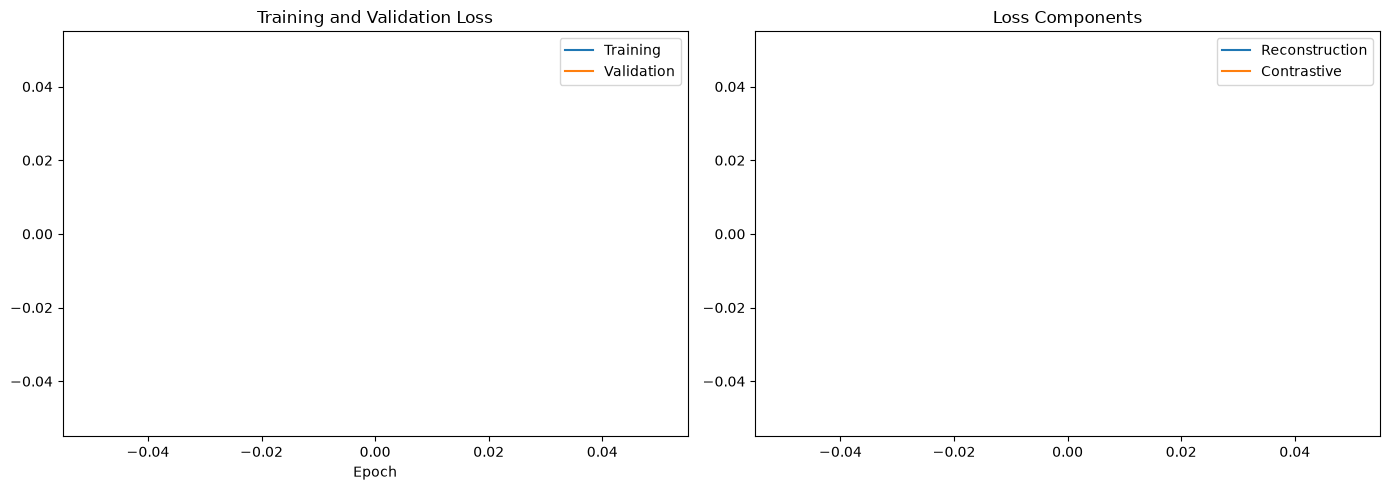

In [24]:
fig, axes = plt.subplots(
    1, 2, figsize=(14, 5)
)

axes[0].plot(
    history["train_loss"],
    label="Training"
)

axes[0].plot(
    history["val_loss"],
    label="Validation"
)

axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(
    history["reconstruction_loss"],
    label="Reconstruction"
)

axes[1].plot(
    history["contrastive_loss"],
    label="Contrastive"
)

axes[1].set_title("Loss Components")
axes[1].legend()

plt.tight_layout()
plt.show()

##### 16) 최적 모델 보존

In [ ]:
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Best SensitiveMamba checkpoint restored.")
print("Validation loss:", checkpoint["best_val_loss"])

##### 17) 이상 점수 계산

In [26]:
@torch.no_grad()
def calculate_anomaly_scores(model, loader):

    model.eval()

    scores = []

    for x in loader:

        x = x.to(DEVICE)

        mean, log_var, _ = model(x)

        point_nll = 0.5 * (
            log_var +
            (x - mean).pow(2) *
            torch.exp(-log_var)
        )

        # Last timestep, averaged over sensors.
        score = point_nll[:, -1, :].mean(dim=1)

        scores.extend(
            score.cpu().numpy().tolist()
        )

    return np.asarray(scores)


# Validation scores from normal-only windows.
val_scores = calculate_anomaly_scores(
    model,
    val_loader
)

# Test scores from normal and anomalous windows.
test_scores = calculate_anomaly_scores(
    model,
    test_loader
)

print("Validation scores:", val_scores.shape)
print("Test scores:", test_scores.shape)

NameError: name 'model' is not defined

##### 18) 임계값 교정

In [ ]:
THRESHOLD_PERCENTILE = 99.0

threshold = np.percentile(
    val_scores,
    THRESHOLD_PERCENTILE
)

print("Anomaly threshold:", threshold)

y_pred = (
    test_scores > threshold
).astype(int)

print("Predicted anomalies:", y_pred.sum())
print("Actual anomalies:", y_test.sum())

##### 19) 성능 평가

In [ ]:
precision = precision_score(
    y_test, y_pred,
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    zero_division=0
)

roc_auc = (
    roc_auc_score(y_test, test_scores)
    if len(np.unique(y_test)) == 2
    else np.nan
)

pr_auc = (
    average_precision_score(y_test, test_scores)
    if len(np.unique(y_test)) == 2
    else np.nan
)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

far = fp / (fp + tn + 1e-8)
mar = fn / (fn + tp + 1e-8)

results = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
        "PR-AUC",
        "False Alarm Rate",
        "Missed Alarm Rate"
    ],
    "Value": [
        precision,
        recall,
        f1,
        roc_auc,
        pr_auc,
        far,
        mar
    ]
})

display(results)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

##### 20) 혼동행렬

In [ ]:
plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Anomaly"],
    yticklabels=["Normal", "Anomaly"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SensitiveMamba - SKAB 0.9")
plt.tight_layout()
plt.show()

##### 21) ROC 및 Precision-Recall 곡선 시각화

In [ ]:
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve
)

if len(np.unique(y_test)) == 2:

    fpr, tpr, _ = roc_curve(
        y_test, test_scores
    )

    pr, rc, _ = precision_recall_curve(
        y_test, test_scores
    )

    fig, axes = plt.subplots(
        1, 2, figsize=(13, 5)
    )

    axes[0].plot(fpr, tpr)
    axes[0].plot(
        [0, 1], [0, 1],
        linestyle="--", color="gray"
    )
    axes[0].set_title(
        f"ROC Curve (AUC={roc_auc:.4f})"
    )
    axes[0].set_xlabel("False Positive Rate")
    axes[0].set_ylabel("True Positive Rate")

    axes[1].plot(rc, pr)
    axes[1].set_title(
        f"PR Curve (AP={pr_auc:.4f})"
    )
    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")

    plt.tight_layout()
    plt.show()

##### 22) 이상 점수 시각화

In [ ]:
plt.figure(figsize=(16, 5))

plt.plot(
    test_scores,
    label="Anomaly score",
    linewidth=1
)

plt.axhline(
    threshold,
    color="red",
    linestyle="--",
    label="Normal validation threshold"
)

anomaly_indices = np.where(y_test == 1)[0]

plt.scatter(
    anomaly_indices,
    test_scores[anomaly_indices],
    color="orange",
    s=8,
    label="Actual anomaly"
)

plt.xlabel("Test window endpoint")
plt.ylabel("MTS-NLL anomaly score")
plt.title("SensitiveMamba anomaly detection")
plt.legend()
plt.tight_layout()
plt.show()

##### 23) change point 탐지 평가
SKAB has two different labels:

- anomaly: point-level anomaly ground truth.

- changepoint: change-point annotations for collective anomalies.

They should be evaluated separately rather than treated as identical labels.


In [ ]:
y_test_changepoint = []

for name in test_files:

    df = experiments[name]

    cp = df["changepoint"].values.astype(int)

    for start in range(
        0,
        len(df) - WINDOW + 1,
        STRIDE
    ):

        end = start + WINDOW

        y_test_changepoint.append(
            cp[end - 1]
        )

y_test_changepoint = np.asarray(
    y_test_changepoint
)

assert len(y_test_changepoint) == len(test_scores)

print(
    "Changepoint annotations:",
    y_test_changepoint.sum()
)

##### 24) 임계치 민감도 분석

In [ ]:
threshold_results = []

for percentile in [95, 97, 98, 99, 99.5]:

    current_threshold = np.percentile(
        val_scores,
        percentile
    )

    predictions = (
        test_scores > current_threshold
    ).astype(int)

    threshold_results.append({
        "Percentile": percentile,
        "Threshold": current_threshold,
        "Precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_test,
            predictions,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(
    threshold_results
)

display(threshold_df)

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Percentile"],
    threshold_df["F1"],
    marker="o",
    label="F1"
)

plt.plot(
    threshold_df["Percentile"],
    threshold_df["Precision"],
    marker="s",
    label="Precision"
)

plt.plot(
    threshold_df["Percentile"],
    threshold_df["Recall"],
    marker="^",
    label="Recall"
)

plt.xlabel("Validation threshold percentile")
plt.ylabel("Metric")
plt.title("Threshold sensitivity analysis")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

##### 25) 결과 저장

In [ ]:
OUTPUT_DIR = Path("./sensitive_mamba_results")
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Save performance metrics.
results.to_csv(
    OUTPUT_DIR / "performance_metrics.csv",
    index=False
)

# Save threshold analysis.
threshold_df.to_csv(
    OUTPUT_DIR / "threshold_analysis.csv",
    index=False
)

# Save individual anomaly scores.
score_results = pd.DataFrame({
    "anomaly_score": test_scores,
    "threshold": threshold,
    "ground_truth": y_test,
    "prediction": y_pred,
    "changepoint": y_test_changepoint
})

score_results.to_csv(
    OUTPUT_DIR / "anomaly_detection_results.csv",
    index=False
)

# Save training history.
pd.DataFrame(history).to_csv(
    OUTPUT_DIR / "training_history.csv",
    index=False
)

print("Results saved to:", OUTPUT_DIR)

##### 26) 하이퍼파라미터 출력 (json)

In [ ]:
import json

experiment_config = {
    **CONFIG,
    "seed": SEED,
    "device": str(DEVICE),
    "input_features": SENSOR_COLUMNS,
    "input_dimension": len(SENSOR_COLUMNS),
    "threshold_percentile": THRESHOLD_PERCENTILE,
    "threshold": float(threshold),
    "best_validation_loss": float(best_val_loss),
    "train_experiments": train_files,
    "validation_experiments": val_files,
    "test_experiments": test_files
}

with open(
    OUTPUT_DIR / "experiment_config.json",
    "w"
) as f:

    json.dump(
        experiment_config,
        f,
        indent=4
    )

print("Experiment configuration saved.")